# Oxford-IIIT Pet Segmentation: Baseline vs. Dilated Bottleneck

A self-contained Kaggle experiment for semantic pet segmentation. It trains a compact U-Net baseline and a controlled variant that changes only the bottleneck convolution dilation. Both runs use the same split, input resolution, augmentation, optimizer, epoch cap, and early-stopping rule.

## Kaggle setup

1. In the Kaggle Notebook editor, select **Settings → Accelerator → GPU T4 ×2**. The setup cell checks that both devices are visible. [Kaggle accelerator guide](https://www.kaggle.com/docs/notebooks)
2. Attach [The Oxford-IIIT Pet Dataset](https://www.kaggle.com/datasets/tanlikesmath/the-oxfordiiit-pet-dataset). The notebook recognizes extracted `images/` and `annotations/trimaps/` folders and the official image and annotation tar archives. Set `DATA_ROOT` to the attached dataset folder if automatic discovery fails.
3. Set `SMOKE_TEST = True` and choose **Run All** to check one short epoch per model. Look for rank 0 on `cuda:0` and rank 1 on `cuda:1` with NCCL. Set `SMOKE_TEST = False` and run all cells again for the full experiment.

Each run uses its own folder under `/kaggle/working/oxford_pet_ddp`. The global training batch is 16, split across the two GPUs.

**Data contract:** Oxford trimap values are `1=pet`, `2=background`, `3=boundary`. This experiment maps 1→foreground and 2→background, and ignores boundary pixels (label 3) in both loss and metrics. Images and masks are resized to 256×256; masks use nearest-neighbor interpolation. Training augmentation is a synchronized random horizontal flip only.


In [6]:
from pathlib import Path
from datetime import datetime, timezone
import json
import os
import sys
import time

import torch

DATA_ROOT = None  # Auto-detect under /kaggle/input. Set a real path if needed.
REQUIRE_OFFICIAL_SPLITS = False  # Fall back to a seeded 80/20 split if the official lists are absent.
SMOKE_TEST = False  # True: 1 epoch per model, small subsets, same dual-GPU launch.
IMAGE_SIZE = 256
BATCH_PER_GPU = 8  # Two GPUs x 8 = 16 images per optimizer step, as in the original.
MAX_EPOCHS = 20    # Per model
PATIENCE = 5       # Per model, by validation mean IoU
LIMIT_TRAIN = None  # Set to an integer to cap the training split.
LIMIT_VAL = None    # Set to an integer to cap the validation split.
LEARNING_RATE = 1e-3
WORKERS_PER_GPU = 0  # Cache is mmap-backed. Try 1 or 2 if input transfer is a bottleneck.
SEED = 42

# Kaggle defaults require both GPUs. These overrides are for local smoke testing only.
DEVICE = "cuda"
PROCESSES = 2

INPUT_ROOT = Path("/kaggle/input")
OUTPUT_ROOT = Path("/kaggle/working/oxford_pet_ddp")
CACHE_PARENT = Path("/kaggle/working")  # Temporary cache is removed after the run.

if any(limit is not None and (not isinstance(limit, int) or limit <= 0)
       for limit in (LIMIT_TRAIN, LIMIT_VAL)):
    raise ValueError("LIMIT_TRAIN and LIMIT_VAL must be positive integers or None.")

if DEVICE not in {"cuda", "cpu"} or PROCESSES < 1 or BATCH_PER_GPU < 1 or WORKERS_PER_GPU < 0:
    raise ValueError("Check DEVICE, PROCESSES, BATCH_PER_GPU, and WORKERS_PER_GPU.")
if IMAGE_SIZE < 16 or IMAGE_SIZE % 8 or min(MAX_EPOCHS, PATIENCE) <= 0:
    raise ValueError("IMAGE_SIZE must be a multiple of 8 and at least 16; epoch cap and patience must be positive.")
if DEVICE == "cuda":
    gpu_count = torch.cuda.device_count()
    if gpu_count < PROCESSES:
        raise RuntimeError(f"Found {gpu_count} visible GPUs. In Kaggle, choose Settings → Accelerator → GPU T4 x2 "
                           "and restart the session before running again.")
    if PROCESSES > 1 and not torch.distributed.is_nccl_available():
        raise RuntimeError("This PyTorch build has no NCCL support. Use Kaggle's built-in Linux GPU environment.")
    for i in range(PROCESSES):
        print(f"GPU {i}: {torch.cuda.get_device_name(i)}")
else:
    print(f"Local CPU mode ({PROCESSES} processes)")

cfg = dict(data_root=DATA_ROOT, require_official=REQUIRE_OFFICIAL_SPLITS,
           smoke_test=SMOKE_TEST, image_size=min(IMAGE_SIZE, 128) if SMOKE_TEST else IMAGE_SIZE,
           batch_per_gpu=BATCH_PER_GPU, max_epochs=1 if SMOKE_TEST else MAX_EPOCHS,
           patience=PATIENCE, learning_rate=LEARNING_RATE, workers_per_gpu=WORKERS_PER_GPU,
           seed=SEED, device=DEVICE, processes=PROCESSES,
           limit_train=LIMIT_TRAIN, limit_val=LIMIT_VAL)
print(f"PyTorch {torch.__version__} | global batch: {BATCH_PER_GPU * PROCESSES} | "
      f"resolution: {cfg['image_size']} px | {'smoke test' if SMOKE_TEST else 'full experiment'}")

GPU 0: Tesla T4
GPU 1: Tesla T4
PyTorch 2.11.0+cu130 | global batch: 16 | resolution: 256 px | full experiment


## Data preparation

Find paired images and trimaps within the same attachment. Resize them once, using nearest-neighbor interpolation for masks. Both training processes read the same temporary, memory-mapped cache (about 1.8 GiB for the full dataset at 256 × 256). The cache is deleted after the run.

In [7]:
from pathlib import Path
import json
import random
import tarfile

import numpy as np
from PIL import Image


def files_by_stem(folder, suffixes):
    return {p.stem: p for p in sorted(folder.iterdir())
            if p.is_file() and p.suffix.lower() in suffixes and not p.name.startswith(".")}


def named_dirs(root, name):
    return ([root] if root.name == name else []) + sorted(p for p in root.rglob(name) if p.is_dir())


def dataset_candidates(root):
    images = [(p, files_by_stem(p, {".jpg", ".jpeg"})) for p in named_dirs(root, "images")]
    masks = [(p, files_by_stem(p, {".png"})) for p in named_dirs(root, "trimaps")]
    candidates = []
    for idir, ipaths in images:
        for mdir, mpaths in masks:
            common = sorted(ipaths.keys() & mpaths.keys())
            if not common:
                continue
            ann = next((p for p in (mdir.parent, *mdir.parents)
                        if (p == root or root in p.parents)
                        and (p / "trainval.txt").is_file() and (p / "test.txt").is_file()), None)
            candidates.append((idir, mdir, ann, ipaths, mpaths, common))
    return candidates


def find_dataset(data_root, input_root, scratch, require_official, progress):
    root = Path(data_root).expanduser().resolve() if data_root else Path(input_root)
    if not root.is_dir():
        raise FileNotFoundError(f"{root} does not exist. Attach the dataset or set DATA_ROOT.")
    # Kaggle inputs can appear directly under input/ or under input/datasets/owner/slug/.
    scopes = [root] if data_root else sorted(p for p in root.iterdir() if p.is_dir())
    if not data_root and (root / "datasets") in scopes:
        scopes.remove(root / "datasets")
        scopes.extend(sorted(p for p in (root / "datasets").glob("*/*") if p.is_dir()))
    candidates = [(candidate, scope) for scope in scopes for candidate in dataset_candidates(scope)]
    if not any(c[2] is not None for c, _ in candidates):
        for scope in scopes:
            archive = {}
            for kind in ("images", "annotations"):
                paths = [p for pattern in (f"{kind}.tar", f"{kind}.tar.gz", f"{kind}.tgz")
                         for p in scope.rglob(pattern) if p.is_file()]
                if paths:
                    archive[kind] = min(paths, key=lambda p: (len(p.parts), str(p)))
            if len(archive) != 2:
                continue
            dest = scratch / f"unpacked_{len(candidates)}"
            dest.mkdir(exist_ok=True)
            for path in archive.values():
                progress(f"Extracting {path.name}")
                print("Extracting", path, flush=True)
                with tarfile.open(path, "r:*") as tar:
                    tar.extractall(dest, filter="data")
            candidates.extend((c, scope) for c in dataset_candidates(dest))
            if any(c[2] is not None for c, _ in candidates):
                break
    if require_official:
        candidates = [(c, s) for c, s in candidates if c[2] is not None]
    if not candidates:
        visible = ", ".join(str(p) for p in scopes[:12]) or "(no attached inputs)"
        raise FileNotFoundError(
            f"Oxford-IIIT Pet files not found. Searched: {visible}. "
            "Set DATA_ROOT to the folder containing images and annotations "
            "(trimaps, trainval.txt, test.txt), or both official tar archives."
        )
    return max(candidates, key=lambda entry: (entry[0][2] is not None,
                                               len(entry[0][5]),
                                               -len(entry[0][0].parts)))[0]


def prepare_data(cfg, input_root, scratch, run_dir, progress):
    progress("Finding the Oxford-IIIT Pet dataset")
    idir, mdir, ann, ipaths, mpaths, common = find_dataset(
        cfg["data_root"], input_root, scratch, cfg["require_official"], progress)
    print(f"Images: {idir}\nTrimaps: {mdir}\nOfficial split directory: {ann}")
    available = set(common)
    rng = random.Random(cfg["seed"])
    if ann is not None:
        def read_ids(filename):
            path = ann / filename
            listed = list(dict.fromkeys(
                line.split()[0] for line in path.read_text(encoding="utf-8-sig").splitlines()
                if line.strip() and not line.lstrip().startswith("#")))
            found = [sid for sid in listed if sid in available]
            if len(found) != len(listed):
                print(f"{path.name}: skipping {len(listed) - len(found)} IDs without a paired image and mask.")
            return found
        trainval, test = read_ids("trainval.txt"), read_ids("test.txt")
    else:
        print("Official split files missing. Using a seeded 80/20 split; test is not the official split.")
        rng.shuffle(common)
        cut = int(0.8 * len(common))
        trainval, test = common[:cut], common[cut:]
        rng = random.Random(cfg["seed"])  # Match the original fallback's separate validation shuffle.
    if set(trainval) & set(test):
        raise ValueError("The trainval and test lists share IDs. Check your dataset copy.")
    rng.shuffle(trainval)
    n_val = max(1, int(0.15 * len(trainval)))
    train, val = trainval[n_val:], trainval[:n_val]
    train, val = train[:cfg["limit_train"]], val[:cfg["limit_val"]]
    if cfg["smoke_test"]:
        train, val, test = train[:48], val[:7], test[:13]
    if not (train and val and test):
        raise ValueError("A data split is empty after pairing images and trimaps.")
    print(f"Using {len(train):,} train, {len(val):,} validation and {len(test):,} test images.")
    ids = train + val + test
    counts = {"train": len(train), "val": len(val), "test": len(test)}
    meta = {"ids": ids, "counts": counts, "official_test_split": ann is not None,
            "images": str(idir), "trimaps": str(mdir)}
    (run_dir / "dataset.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")

    # Resize once; both workers read the same compact cache without re-decoding JPEGs every epoch.
    size = cfg["image_size"]
    cache_path = scratch / "pixels.npy"
    cache = np.lib.format.open_memmap(cache_path, mode="w+", dtype=np.uint8,
                                      shape=(len(ids), size, size, 4))
    title = "Preparing image and mask cache"
    total = len(ids)
    progress(title, 0, total, "images")
    last_update = time.monotonic()
    try:
        for i, sid in enumerate(ids):
            with Image.open(ipaths[sid]) as im:
                cache[i, :, :, :3] = np.asarray(
                    im.convert("RGB").resize((size, size), Image.Resampling.BILINEAR))
            with Image.open(mpaths[sid]) as im:
                if im.mode not in ("L", "P"):
                    raise ValueError(f"{mpaths[sid]} is not an indexed Oxford trimap (mode {im.mode}).")
                raw = np.asarray(im.resize((size, size), Image.Resampling.NEAREST), dtype=np.uint8)
            # Palette indices are class IDs. Don't convert a palette mask to grayscale.
            cache[i, :, :, 3] = np.where(raw == 1, 1, np.where(raw == 2, 0, 255))
            if i % 250 == 0 and i and not np.any((raw == 1) | (raw == 2)):
                print(f"Warning: {sid} has no labeled foreground or background after resizing.")
            now = time.monotonic()
            if i == 0 or i + 1 == total or now - last_update >= 0.5:
                progress(title, i + 1, total, "images")
                last_update = now
        progress("Saving prepared data")
        cache.flush()
    finally:
        del cache
    return cache_path

## Model and distributed worker

The next cell holds the Python script that the notebook launches with PyTorch's [torchrun](https://docs.pytorch.org/docs/stable/elastic/run.html). It uses [DistributedDataParallel](https://docs.pytorch.org/docs/stable/generated/torch.nn.parallel.DistributedDataParallel.html), one process per GPU, with FP16 autocast and gradient scaling. Each training process samples a different share of the same shuffled epoch. Validation and test shards have no padding; their confusion matrices are summed before calculating IoU.

Both GPUs train the baseline first, then the dilated model. Both models start from identical weights and use the same shuffled indices and horizontal flips at each matching epoch. Each model trains up to `MAX_EPOCHS` and stops early after `PATIENCE` epochs without validation improvement. Rank 0 saves the best checkpoint for each model. Both GPUs evaluate the held-out split after training finishes.

In [8]:
TRAIN_SCRIPT = r'''
from datetime import timedelta
from pathlib import Path
import json
import math
import os
import random
import sys
import time

import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
from torch.utils.data import DataLoader, Dataset, DistributedSampler, Sampler


class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dilation=1):
        super().__init__()
        self.net=nn.Sequential(
            nn.Conv2d(in_ch,out_ch,3,padding=dilation,dilation=dilation,bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch,out_ch,3,padding=1,bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
    def forward(self,x): return self.net(x)

class SmallUNet(nn.Module):
    def __init__(self, bottleneck_dilation=1):
        super().__init__()
        self.enc1=ConvBlock(3,32); self.pool1=nn.MaxPool2d(2)
        self.enc2=ConvBlock(32,64); self.pool2=nn.MaxPool2d(2)
        self.enc3=ConvBlock(64,128); self.pool3=nn.MaxPool2d(2)
        self.bottleneck=ConvBlock(128,256,dilation=bottleneck_dilation)
        self.up3=nn.ConvTranspose2d(256,128,2,2); self.dec3=ConvBlock(256,128)
        self.up2=nn.ConvTranspose2d(128,64,2,2); self.dec2=ConvBlock(128,64)
        self.up1=nn.ConvTranspose2d(64,32,2,2); self.dec1=ConvBlock(64,32)
        self.head=nn.Conv2d(32,2,1)
    def forward(self,x):
        a=self.enc1(x); b=self.enc2(self.pool1(a)); c=self.enc3(self.pool2(b))
        z=self.bottleneck(self.pool3(c))
        z=self.dec3(torch.cat([self.up3(z),c],1))
        z=self.dec2(torch.cat([self.up2(z),b],1))
        z=self.dec1(torch.cat([self.up1(z),a],1))
        return self.head(z)


class PetCache(Dataset):
    def __init__(self, pixels, offset, count, seed, augment=False):
        self.path = str(pixels)
        self.offset, self.count, self.seed = offset, count, seed
        self.augment = augment
        self.epoch = 0
        self.pixels = None  # Open lazily inside each DataLoader worker.

    def __len__(self):
        return self.count

    def __getitem__(self, i):
        if self.pixels is None:
            self.pixels = np.load(self.path, mmap_mode="r")
        sample = self.pixels[self.offset + i]
        if self.augment and random.Random(self.seed + self.epoch * self.count + i).random() < 0.5:
            sample = sample[:, ::-1, :]
        return np.array(sample, copy=True), i


class EvalShard(Sampler):
    """Disjoint shards without padding; each validation/test item contributes exactly once."""
    def __init__(self, dataset, rank, world):
        self.indices = range(rank, len(dataset), world)

    def __iter__(self):
        return iter(self.indices)

    def __len__(self):
        return len(self.indices)


def split_batch(samples, device):
    samples = samples.to(device, non_blocking=True)
    image = samples[..., :3].permute(0, 3, 1, 2).to(dtype=torch.float32,
                                                   memory_format=torch.channels_last)
    return image.mul_(2.0 / 255).sub_(1), samples[..., 3].long().contiguous()


def autocast(device):
    return torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda")


def sum_across_ranks(tensor, async_op=False):
    if dist.is_initialized():
        return dist.all_reduce(tensor, op=dist.ReduceOp.SUM, async_op=async_op)


def validate_scores(cm):
    cm = cm.detach().cpu().numpy().astype(np.float64)
    denom = cm.sum(axis=0) + cm.sum(axis=1) - np.diag(cm)
    iou = [float(cm[i, i] / denom[i]) if denom[i] else None for i in range(2)]
    defined = [x for x in iou if x is not None]
    if not defined:
        raise ValueError("No labeled foreground or background pixels found during evaluation.")
    return iou, float(np.mean(defined))


def report_progress(title, step, total):
    event = {"title": title, "step": step, "total": total, "unit": "batches"}
    print("NOTEBOOK_PROGRESS " + json.dumps(event), flush=True)


def track_batches(batches, label, phase):
    if label is None:
        yield from batches
        return

    title = f"{label} | {phase}"
    total = len(batches)
    report_progress(title, 0, total)
    last_update = time.monotonic()
    for step, batch in enumerate(batches, start=1):
        yield batch
        now = time.monotonic()
        if step == 1 or step == total or now - last_update >= 1:
            report_progress(title, step, total)
            last_update = now


@torch.inference_mode()
def evaluate(model, batches, device, collect_errors=False, limit=6, progress_label=None,
             progress_phase="validation (rank 0 shard)"):
    # Invoke the raw model: the shards may have different numbers of batches, including zero.
    # Broadcast batch-normalization buffers once so every rank evaluates the same model.
    model.eval()
    if dist.is_initialized():
        for buffer in model.buffers():
            dist.broadcast(buffer, src=0)
    cm = torch.zeros((2, 2), dtype=torch.int64, device=device)
    per_image = []
    for samples, ids in track_batches(batches, progress_label, progress_phase):
        x, y = split_batch(samples, device)
        with autocast(device):
            pred = model(x).argmax(1)
        bg, pet = y == 0, y == 1
        pred_pet = pred == 1
        dims = (1, 2) if collect_errors else None
        if collect_errors:
            # Compute errors per test image during the same batched forward passes.
            a = (bg & ~pred_pet).sum(dims)
            b = (bg & pred_pet).sum(dims)
            c = (pet & ~pred_pet).sum(dims)
            d = (pet & pred_pet).sum(dims)
            rows = torch.stack((a, b, c, d), dim=1)
            cm += rows.sum(0).reshape(2, 2)
            per_image.append((ids, rows))
        else:
            cm += torch.stack(((bg & ~pred_pet).sum(), (bg & pred_pet).sum(),
                               (pet & ~pred_pet).sum(), (pet & pred_pet).sum())).reshape(2, 2)
    sum_across_ranks(cm)
    picks = []
    if collect_errors and per_image:
        ids = torch.cat([x[0] for x in per_image]).tolist()
        counts = torch.cat([x[1] for x in per_image]).cpu().tolist()
        errors = [((b + c) / (a + b + c + d), i)
                  for i, (a, b, c, d) in zip(ids, counts) if a + b + c + d]
        representative = [("representative", err, i) for err, i in errors if err < 0.15][:limit]
        highest = [("highest", err, i) for err, i in sorted(errors, reverse=True)[:limit]]
        picks = representative + highest
    return cm, picks


def train_epoch(model, batches, optimizer, scaler, device, world, progress_label):
    model.train()
    total_nll = torch.zeros((), dtype=torch.float64, device=device)
    total_valid = torch.zeros((), dtype=torch.int64, device=device)
    for samples, _ in track_batches(batches, progress_label, "training"):
        x, y = split_batch(samples, device)
        local_count = (y != 255).sum()
        global_count = local_count.clone()
        count_work = sum_across_ranks(global_count, async_op=True)
        optimizer.zero_grad(set_to_none=True)
        with autocast(device):
            nll = F.cross_entropy(model(x), y, ignore_index=255, reduction="sum")
        if count_work is not None:
            count_work.wait()
        # DDP averages gradients. Multiplying by world size gives the true
        # mean over all labeled pixels, even when trimap coverage differs by rank.
        loss = nll * (world / global_count.clamp_min(1))
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_nll += nll.detach()
        total_valid += local_count
    sum_across_ranks(total_nll)
    sum_across_ranks(total_valid)
    return float((total_nll / total_valid.clamp_min(1)).item())


@torch.inference_mode()
def latency(model, dataset, device, batch_size, smoke):
    # Reuse a fixed batch in device memory. Measure model forwards averaged per image.
    n = min(batch_size, len(dataset))
    samples = torch.from_numpy(np.stack([dataset[i][0] for i in range(n)]))
    x, _ = split_batch(samples, device)
    warmup, repeats = (2, 3) if smoke else (10, 50)
    model.eval()
    with autocast(device):
        for _ in range(warmup):
            model(x)
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        t0 = time.perf_counter()
        for _ in range(repeats):
            model(x)
        if device.type == "cuda":
            torch.cuda.synchronize(device)
    return {"ms_per_image": (time.perf_counter() - t0) * 1000 / (repeats * n),
            "device": torch.cuda.get_device_name(device) if device.type == "cuda" else "CPU",
            "precision": "FP16 autocast" if device.type == "cuda" else "FP32",
            "batch_size": n, "warmup": warmup, "repeats": repeats}


@torch.inference_mode()
def save_examples(model, dataset, picks, device, output_path):
    representative = sorted((item for item in picks if item[0] == "representative"),
                            key=lambda item: item[2])[:6]
    highest = sorted((item for item in picks if item[0] == "highest"),
                     key=lambda item: (item[1], item[2]), reverse=True)[:6]
    items = representative + highest
    if not items:
        return
    samples = torch.from_numpy(np.stack([dataset[i][0] for _, _, i in items]))
    x, y = split_batch(samples, device)
    with autocast(device):
        pred = torch.cat([model(part).argmax(1).to(torch.uint8).cpu() for part in x.split(4)])
    np.savez_compressed(output_path, images=samples[..., :3].numpy(), masks=y.cpu().numpy().astype(np.uint8),
                        predictions=pred.numpy(), groups=[group for group, _, _ in items],
                        errors=[err for _, err, _ in items], indices=[i for _, _, i in items])


def run(run_dir, pixels, cfg, device, rank, world):
    is_main = rank == 0
    seed = cfg["seed"]
    random.seed(seed)
    torch.manual_seed(seed)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(seed)
    meta = json.loads((run_dir / "dataset.json").read_text(encoding="utf-8"))
    counts = meta["counts"]
    batch_size = cfg["batch_per_gpu"]
    train = PetCache(pixels, 0, counts["train"], seed, augment=True)
    val = PetCache(pixels, counts["train"], counts["val"], seed)
    test = PetCache(pixels, counts["train"] + counts["val"], counts["test"], seed)
    train_sampler = DistributedSampler(train, num_replicas=world, rank=rank, seed=seed)
    loader_opts = {"batch_size": batch_size, "pin_memory": device.type == "cuda",
                   "num_workers": cfg["workers_per_gpu"]}
    if loader_opts["num_workers"]:
        # Start children without inheriting a live CUDA/NCCL context.
        loader_opts.update(multiprocessing_context="spawn", prefetch_factor=2)
    train_loader = DataLoader(train, sampler=train_sampler, **loader_opts)
    val_loader = DataLoader(val, sampler=EvalShard(val, rank, world), **loader_opts)
    test_loader = DataLoader(test, sampler=EvalShard(test, rank, world), **loader_opts)
    if is_main:
        print(f"Global batch={batch_size * world}, steps/epoch={len(train_loader)}, training examples="
              f"{len(train):,}. The sampler repeats {train_sampler.total_size - len(train)} "
              "example(s) per epoch to give ranks equal sample counts.", flush=True)

    initial_state = SmallUNet(1).state_dict()
    models = {}
    for key, dilation in (("baseline", 1), ("dilated", 2)):
        raw = SmallUNet(dilation)
        raw.load_state_dict(initial_state)
        raw.to(device=device, memory_format=torch.channels_last)
        parallel = (DDP(raw, device_ids=[device.index] if device.type == "cuda" else None,
                        gradient_as_bucket_view=True) if world > 1 else raw)
        models[key] = {"raw": raw, "model": parallel, "best": -math.inf, "stale": 0,
                       "optimizer": torch.optim.Adam(parallel.parameters(), lr=cfg["learning_rate"]),
                       "scaler": torch.amp.GradScaler("cuda", enabled=device.type == "cuda"),
                       "history": [], "stop": "epoch_cap"}

    for key, m in models.items():
        for epoch in range(1, cfg["max_epochs"] + 1):
            train.epoch = epoch
            train_sampler.set_epoch(epoch)
            label = f"{key} | epoch {epoch:02d}/{cfg['max_epochs']}"
            progress_label = label if is_main else None
            t0 = time.perf_counter()
            train_loss = train_epoch(m["model"], train_loader, m["optimizer"], m["scaler"],
                                     device, world, progress_label)
            cm, _ = evaluate(m["raw"], val_loader, device, progress_label=progress_label)
            _, val_miou = validate_scores(cm)
            seconds = time.perf_counter() - t0
            m["history"].append({"epoch": epoch, "train_loss": train_loss,
                                 "val_miou": val_miou, "epoch_seconds": seconds})
            if val_miou > m["best"]:
                m["best"], m["stale"], m["best_epoch"] = val_miou, 0, epoch
                if is_main:
                    state = {k: v.detach().cpu() for k, v in m["raw"].state_dict().items()}
                    checkpoint = {"model_state_dict": state, "dilation": 1 if key == "baseline" else 2,
                                  "epoch": epoch, "val_miou": val_miou, "image_size": cfg["image_size"]}
                    tmp = run_dir / f"{key}.pt.tmp"
                    torch.save(checkpoint, tmp)
                    tmp.replace(run_dir / f"{key}_best.pt")
            else:
                m["stale"] += 1
                if m["stale"] >= cfg["patience"]:
                    m["stop"] = "early_stopping"
            if is_main:
                history_tmp = run_dir / "history.json.tmp"
                history_tmp.write_text(
                    json.dumps({name: model["history"] for name, model in models.items()}, indent=2),
                    encoding="utf-8")
                history_tmp.replace(run_dir / "history.json")
                print(f"{label} | complete | train loss={train_loss:.4f} | val mIoU={val_miou:.4f} | "
                      f"{seconds:.1f}s | best epoch={m['best_epoch']}", flush=True)
            if m["stop"] == "early_stopping":
                if is_main:
                    print(f"{label} | early stopping | best val mIoU={m['best']:.4f}", flush=True)
                break

    if world > 1:
        dist.barrier()  # Rank 0 must finish writing the final checkpoints before other ranks load them.
    results = {}
    if is_main:
        print("Training complete. Evaluating the best checkpoints on the held-out split.")
    for key, m in models.items():
        checkpoint = torch.load(run_dir / f"{key}_best.pt", map_location="cpu", weights_only=True)
        raw = m["raw"]
        raw.load_state_dict(checkpoint["model_state_dict"])
        cm, picks = evaluate(raw, test_loader, device, collect_errors=key == "dilated",
                             progress_label=key if is_main else None,
                             progress_phase="held-out evaluation (rank 0 shard)")
        if key == "dilated":
            if world > 1:
                from_ranks = [None] * world if is_main else None
                dist.gather_object(picks, object_gather_list=from_ranks, dst=0)
                if is_main:
                    picks = [p for shard in from_ranks for p in shard]
            if is_main:
                save_examples(raw, test, picks, device, run_dir / "examples.npz")
        if is_main:
            (bg, pet), miou = validate_scores(cm)
            results[key] = {"background_IoU": bg, "pet_IoU": pet, "mIoU": miou,
                            "test_confusion_matrix": cm.cpu().tolist(),
                            "parameters": sum(p.numel() for p in raw.parameters()),
                            "best_epoch": m["best_epoch"], "epochs_run": len(m["history"]),
                            "stop_reason": m["stop"],
                            "latency": latency(raw, test, device, batch_size * world, cfg["smoke_test"])}
            print(f"{key} held-out mIoU: {miou:.4f}")
    if is_main:
        summary = {"training_processes": world, "official_test_split": meta["official_test_split"],
                   "smoke_test": cfg["smoke_test"], "elapsed_minutes": (time.time() - cfg["started_at"]) / 60,
                   "results": results}
        (run_dir / "results.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    if world > 1:
        dist.barrier()


def main(local_cpu_rank=None):
    run_dir, pixels = map(Path, sys.argv[1:3])
    cfg = json.loads((run_dir / "config.json").read_text(encoding="utf-8"))
    local_rank = int(os.environ.get("LOCAL_RANK", "0"))
    world = int(os.environ.get("WORLD_SIZE", "1"))
    rank = int(os.environ.get("RANK", "0"))
    torch.set_num_threads(1 if world > 1 else 2)
    if cfg["device"] == "cuda":
        if torch.cuda.device_count() < world:
            raise RuntimeError(f"Found {torch.cuda.device_count()} GPUs for {world} training processes.")
        torch.cuda.set_device(local_rank)
        device = torch.device("cuda", local_rank)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
        backend = "nccl"
        name = torch.cuda.get_device_name(device)
    else:
        device, backend, name = torch.device("cpu"), "gloo", "CPU"
    if local_cpu_rank is not None:
        rank, world = local_cpu_rank, cfg["processes"]
        torch.set_num_threads(1)
    if world != cfg["processes"]:
        raise RuntimeError(f"Expected {cfg['processes']} processes, found {world}. Use the notebook launch cell.")
    if world > 1:
        kwargs = {}
        if local_cpu_rank is not None:
            kwargs.update(store=dist.FileStore(str(pixels.with_name("ddp_store")), world),
                          rank=rank, world_size=world)
        dist.init_process_group(backend=backend, timeout=timedelta(minutes=5), **kwargs)
    try:
        print(f"rank {rank} on {device} ({name}) | backend={backend if world > 1 else 'single process'}",
              flush=True)
        run(run_dir, pixels, cfg, device, rank, world)
    finally:
        if dist.is_initialized():
            dist.destroy_process_group()


if __name__ == "__main__":
    config = json.loads((Path(sys.argv[1]) / "config.json").read_text(encoding="utf-8"))
    if os.name == "nt" and config["device"] == "cpu" and config["processes"] > 1:
        # Local verification on Windows, where NCCL isn't supported.
        torch.multiprocessing.spawn(main, nprocs=config["processes"], join=True)
    else:
        main()
'''

## Launch training

The live status above the launch cell log shows data preparation, worker startup, and batch progress during each baseline and dilated epoch. Validation progress follows rank 0's shard. The cell also prints progress milestones. Each completed epoch adds a permanent summary with training loss, validation mean IoU across both GPUs, elapsed time, and the best epoch so far.

The run folder stores `train.log`, `history.json`, the best checkpoints, configuration, and split IDs.


In [26]:
import subprocess
from html import escape
from queue import Empty, Queue
from tempfile import TemporaryDirectory
from threading import Thread
from uuid import uuid4

from IPython.display import HTML, display


class LiveProgress:
    def __init__(self):
        self.title = ""
        self.phase_started = time.monotonic()
        self.handle = None

    def update(self, title, step=None, total=None, unit="", detail=""):
        now = time.monotonic()
        if title != self.title:
            self.title = title
            self.phase_started = now
        self.step, self.total, self.unit, self.detail = step, total, unit, detail
        self.refresh()

    def refresh(self):
        elapsed = int(time.monotonic() - self.phase_started)
        counts = ""
        bar = ""
        if self.total:
            percent = 100 * self.step / self.total
            counts = f"{self.step:,} / {self.total:,} {escape(self.unit)} ({percent:.0f}%) · "
            bar = (f'<progress value="{self.step}" max="{self.total}" style="width:100%">'
                   f"{percent:.0f}%</progress><br>")
        detail = f"<br><small>{escape(self.detail)}</small>" if self.detail else ""
        output = HTML(f'<div style="max-width:36rem;margin:0.4em 0 0.8em">'
                      f"<strong>{escape(self.title)}</strong><br>{bar}"
                      f"{counts}{elapsed // 60}m {elapsed % 60:02d}s in this phase{detail}</div>")
        if self.handle is None:
            self.handle = display(output, display_id=True)
        else:
            self.handle.update(output)


def read_worker_lines(stream, messages):
    try:
        for line in stream:
            messages.put(line)
    finally:
        messages.put(None)


def show_worker_output(child, log, progress):
    messages = Queue()
    reader = Thread(target=read_worker_lines, args=(child.stdout, messages), daemon=True)
    reader.start()
    last_refresh = time.monotonic()
    progress_prefix = "NOTEBOOK_PROGRESS "
    last_text_bucket = -1
    while True:
        try:
            line = messages.get(timeout=2)
        except Empty:
            progress.refresh()
            last_refresh = time.monotonic()
            continue
        if line is None:
            break
        if line.startswith(progress_prefix):
            event = json.loads(line[len(progress_prefix):])
            progress.update(**event)
            step, total = event["step"], event["total"]
            percent = 100 * step / total if total else 0
            message = f"{event['title']} | {step}/{total} {event['unit']} ({percent:.0f}%)"
            log.write(message + "\n")
            # Keep a few progress lines readable in the saved cell output.
            bucket = (4 * step) // max(1, total)
            if step == 0 or bucket > last_text_bucket:
                print(message, flush=True)
                last_text_bucket = bucket
            last_refresh = time.monotonic()
        else:
            log.write(line)
            print(line, end="", flush=True)
            if progress.title == "Starting training workers":
                progress.update(progress.title, detail=line.strip())
            elif time.monotonic() - last_refresh >= 2:
                progress.refresh()
                last_refresh = time.monotonic()
        log.flush()
    return child.wait()


started_at = time.time()
cfg.update(started_at=started_at)
tag = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
run_dir = (OUTPUT_ROOT / f"{'smoke' if SMOKE_TEST else 'full'}_{tag}_{uuid4().hex[:6]}").resolve()
run_dir.mkdir(parents=True)
(run_dir / "config.json").write_text(json.dumps(cfg, indent=2), encoding="utf-8")
CACHE_PARENT.mkdir(parents=True, exist_ok=True)
progress = LiveProgress()
try:
    with TemporaryDirectory(prefix=".oxford_pet_", dir=CACHE_PARENT) as tmp_dir:
        scratch = Path(tmp_dir).resolve()
        pixels = prepare_data(cfg, INPUT_ROOT, scratch, run_dir, progress.update)
        trainer = scratch / "train_oxford_pet.py"
        trainer.write_text(TRAIN_SCRIPT, encoding="utf-8")
        cmd = [sys.executable, "-u"]
        if PROCESSES > 1 and os.name != "nt":
            cmd += ["-m", "torch.distributed.run", "--standalone", "--nnodes=1",
                    f"--nproc-per-node={PROCESSES}", "--max-restarts=0"]
        cmd += [str(trainer), str(run_dir), str(pixels)]
        worker_env = {**os.environ, "PYTHONUNBUFFERED": "1", "OMP_NUM_THREADS": "1", "MKL_NUM_THREADS": "1"}
        if DEVICE == "cuda" and PROCESSES > 1:
            # Some virtualized GPUs cannot use peer-to-peer over PCIe.
            worker_env.setdefault("NCCL_P2P_DISABLE", "1")
        progress.update("Starting training workers", detail=f"Launching {PROCESSES} processes")
        print(f"Run folder: {run_dir}", flush=True)
        with (run_dir / "train.log").open("w", encoding="utf-8") as log, subprocess.Popen(
            cmd, env=worker_env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, encoding="utf-8", errors="replace",
        ) as child:
            try:
                status = show_worker_output(child, log, progress)
            except BaseException:
                if child.poll() is None:
                    # Allow torchrun to stop its workers on a notebook interrupt.
                    try:
                        child.wait(timeout=8)
                    except subprocess.TimeoutExpired:
                        child.terminate()
                raise
        if status:
            raise RuntimeError(f"Training exited with status {status}. See {run_dir / 'train.log'}.")
except KeyboardInterrupt:
    progress.update("Run interrupted", detail=f"Run folder: {run_dir}")
    raise
except Exception as exc:
    failed_phase = progress.title
    progress.update(f"Run failed during {failed_phase.lower()}", detail=str(exc))
    raise
else:
    progress.update("Run complete", detail=f"{(time.time() - started_at) / 60:.1f} min total · {run_dir}")


Images: /kaggle/input/datasets/devdgohil/the-oxfordiiit-pet-dataset/images/images
Trimaps: /kaggle/input/datasets/devdgohil/the-oxfordiiit-pet-dataset/annotations/annotations/trimaps
Official split directory: /kaggle/input/datasets/devdgohil/the-oxfordiiit-pet-dataset/annotations/annotations
Using 3,128 train, 552 validation and 3,669 test images.
Run folder: /kaggle/working/oxford_pet_ddp/full_20261114_150454_05d10a
rank 1 on cuda:1 (Tesla T4) | backend=ncclrank 0 on cuda:0 (Tesla T4) | backend=nccl

Global batch=16, steps/epoch=196, training examples=3,128. The sampler repeats 0 example(s) per epoch to give ranks equal sample counts.
baseline | epoch 01/20 | training | 0/196 batches (0%)
baseline | epoch 01/20 | training | 61/196 batches (31%)
baseline | epoch 01/20 | training | 105/196 batches (54%)
baseline | epoch 01/20 | training | 147/196 batches (75%)
baseline | epoch 01/20 | training | 196/196 batches (100%)
baseline | epoch 01/20 | validation (rank 0 shard) | 0/35 batches (0%

In [4]:
from pathlib import Path
import torch

ROOT = Path("/kaggle/working/oxford_pet_ddp")
RUN_PATTERN = "full_20261114_150454_05d10a_plus*"

required = ("baseline_best.pt", "dilated_best.pt", "results.json")
completed = [
    folder for folder in ROOT.glob(RUN_PATTERN)
    if folder.is_dir() and all((folder / name).is_file() for name in required)
]

if not completed:
    raise FileNotFoundError(
        f"No completed run matches {RUN_PATTERN!r} in {ROOT}. "
        "Check that the run contains both checkpoints and results.json."
    )

run_dir = max(completed, key=lambda folder: (folder / "results.json").stat().st_mtime)

checkpoints = {
    name: torch.load(
        run_dir / f"{name}_best.pt", map_location="cpu", weights_only=True
    )
    for name in ("baseline", "dilated")
}
baseline_weights = checkpoints["baseline"]["model_state_dict"]
dilated_weights = checkpoints["dilated"]["model_state_dict"]

print(f"Loaded from {run_dir}")
for name, checkpoint in checkpoints.items():
    print(f"{name} | best epoch {checkpoint['epoch']} | val mIoU {checkpoint['val_miou']:.4f}")

Loaded from /kaggle/working/oxford_pet_ddp/full_20261114_150454_05d10a_plus20_dcbf33
baseline | best epoch 39 | val mIoU 0.8958
dilated | best epoch 38 | val mIoU 0.9054


In [29]:
from shutil import copy2

EXTRA_EPOCHS = 20
previous = Path(run_dir).resolve()
resume_cfg = json.loads((previous / "config.json").read_text(encoding="utf-8"))

if resume_cfg["smoke_test"]:
    raise ValueError("Complete a full run with SMOKE_TEST = False first.")

resume_cfg.update(
    max_epochs=EXTRA_EPOCHS,
    patience=EXTRA_EPOCHS + 1,
    started_at=time.time(),
)

anchor = (
    '    for key, m in models.items():\n'
    '        for epoch in range(1, cfg["max_epochs"] + 1):'
)
resume_block = '''    previous_history = json.loads(
        (run_dir / "resume_history.json").read_text(encoding="utf-8")
    )
    for key, m in models.items():
        checkpoint = torch.load(
            run_dir / f"{key}_best.pt", map_location="cpu", weights_only=True
        )
        m["raw"].load_state_dict(checkpoint["model_state_dict"])
        m["history"] = previous_history[key]
        m["best"] = checkpoint["val_miou"]
        m["best_epoch"] = checkpoint["epoch"]
        last_epoch = m["history"][-1]["epoch"]
        final_epoch = last_epoch + cfg["max_epochs"]
        for epoch in range(last_epoch + 1, final_epoch + 1):'''

assert anchor in TRAIN_SCRIPT, "Use this cell with the updated dual-T4 notebook."
resume_script = TRAIN_SCRIPT.replace(anchor, resume_block, 1).replace(
    "epoch {epoch:02d}/{cfg['max_epochs']}", "epoch {epoch:02d}/{final_epoch}", 1
)

continued = previous.parent / f"{previous.name}_plus{EXTRA_EPOCHS}_{uuid4().hex[:6]}"
continued.mkdir()
copy2(previous / "history.json", continued / "resume_history.json")
for key in ("baseline", "dilated"):
    copy2(previous / f"{key}_best.pt", continued / f"{key}_best.pt")
(continued / "config.json").write_text(json.dumps(resume_cfg, indent=2), encoding="utf-8")

progress = LiveProgress()
workers = resume_cfg["processes"]

try:
    with TemporaryDirectory(prefix=".oxford_pet_resume_", dir=CACHE_PARENT) as tmp:
        scratch = Path(tmp)
        pixels = prepare_data(resume_cfg, INPUT_ROOT, scratch, continued, progress.update)

        old_data = json.loads((previous / "dataset.json").read_text(encoding="utf-8"))
        new_data = json.loads((continued / "dataset.json").read_text(encoding="utf-8"))
        if any(old_data[key] != new_data[key] for key in ("ids", "counts")):
            raise ValueError("The dataset split differs from the previous run.")

        trainer = scratch / "train_oxford_pet.py"
        trainer.write_text(resume_script, encoding="utf-8")

        cmd = [sys.executable, "-u"]
        if workers > 1:
            cmd += [
                "-m", "torch.distributed.run", "--standalone", "--nnodes=1",
                f"--nproc-per-node={workers}", "--max-restarts=0",
            ]
        cmd += [str(trainer), str(continued), str(pixels)]

        worker_env = {**os.environ, "PYTHONUNBUFFERED": "1", "OMP_NUM_THREADS": "1"}
        worker_env.setdefault("NCCL_P2P_DISABLE", "1")
        progress.update("Starting training workers", detail=f"Launching {workers} processes")

        with (continued / "train.log").open("w", encoding="utf-8") as log:
            with subprocess.Popen(
                cmd, env=worker_env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                text=True, encoding="utf-8", errors="replace",
            ) as child:
                try:
                    status = show_worker_output(child, log, progress)
                except KeyboardInterrupt:
                    child.terminate()
                    raise

        if status:
            raise RuntimeError(f"Training exited with status {status}. See {continued / 'train.log'}.")
except BaseException:
    progress.update("Continuation stopped", detail=f"Run folder: {continued}")
    raise

run_dir = continued
progress.update("Run complete", detail=f"Run folder: {run_dir}")

Images: /kaggle/input/datasets/devdgohil/the-oxfordiiit-pet-dataset/images/images
Trimaps: /kaggle/input/datasets/devdgohil/the-oxfordiiit-pet-dataset/annotations/annotations/trimaps
Official split directory: /kaggle/input/datasets/devdgohil/the-oxfordiiit-pet-dataset/annotations/annotations
Using 3,128 train, 552 validation and 3,669 test images.
rank 0 on cuda:0 (Tesla T4) | backend=nccl
Global batch=16, steps/epoch=196, training examples=3,128. The sampler repeats 0 example(s) per epoch to give ranks equal sample counts.
rank 1 on cuda:1 (Tesla T4) | backend=nccl
baseline | epoch 21/40 | training | 0/196 batches (0%)
baseline | epoch 21/40 | training | 49/196 batches (25%)
baseline | epoch 21/40 | training | 110/196 batches (56%)
baseline | epoch 21/40 | training | 155/196 batches (79%)
baseline | epoch 21/40 | training | 196/196 batches (100%)
baseline | epoch 21/40 | validation (rank 0 shard) | 0/35 batches (0%)
baseline | epoch 21/40 | validation (rank 0 shard) | 35/35 batches (1

## Held-out results

The table compares background IoU, pet IoU, mean IoU, model size, and inference latency. Latency is timed on one GPU with a fixed batch already on the device. The curves show the validation score used for checkpoint selection. Examples show dilated-model predictions below 15% pixel error and the largest-error predictions from the held-out split. Pixel error excludes the annotated boundary.

Results on the official test split. Processes: 2, elapsed: 10.0 min.
Model                                BG IoU  Pet IoU     mIoU      Params   ms/image Best / total epochs
Baseline (dilation 1)                0.9311   0.8677   0.8994   1,927,042      2.611         39 / 40 (epoch_cap)
Dilated bottleneck (dilation 2)      0.9377   0.8811   0.9094   1,927,042      2.619         38 / 40 (epoch_cap)
Latency: single Tesla T4, FP16 autocast, batch 16; 10 warmup + 50 timed forwards. Excludes reading data and host-to-device transfer.


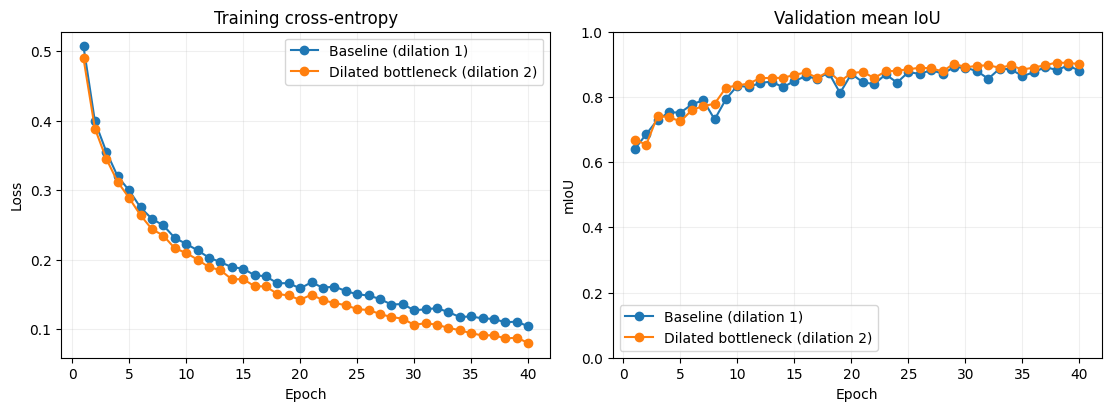

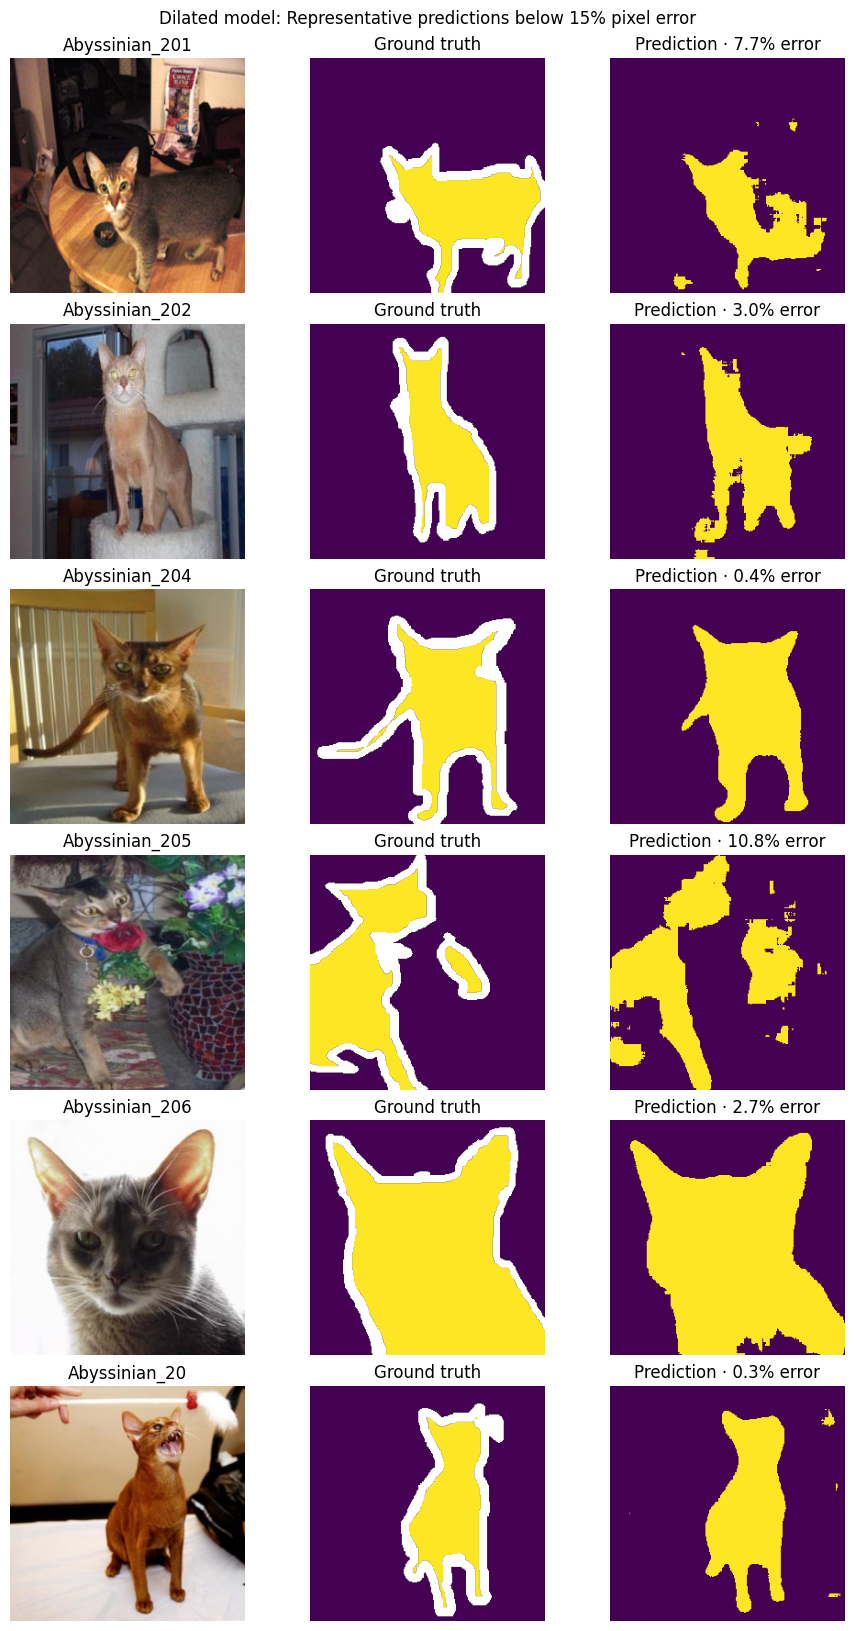

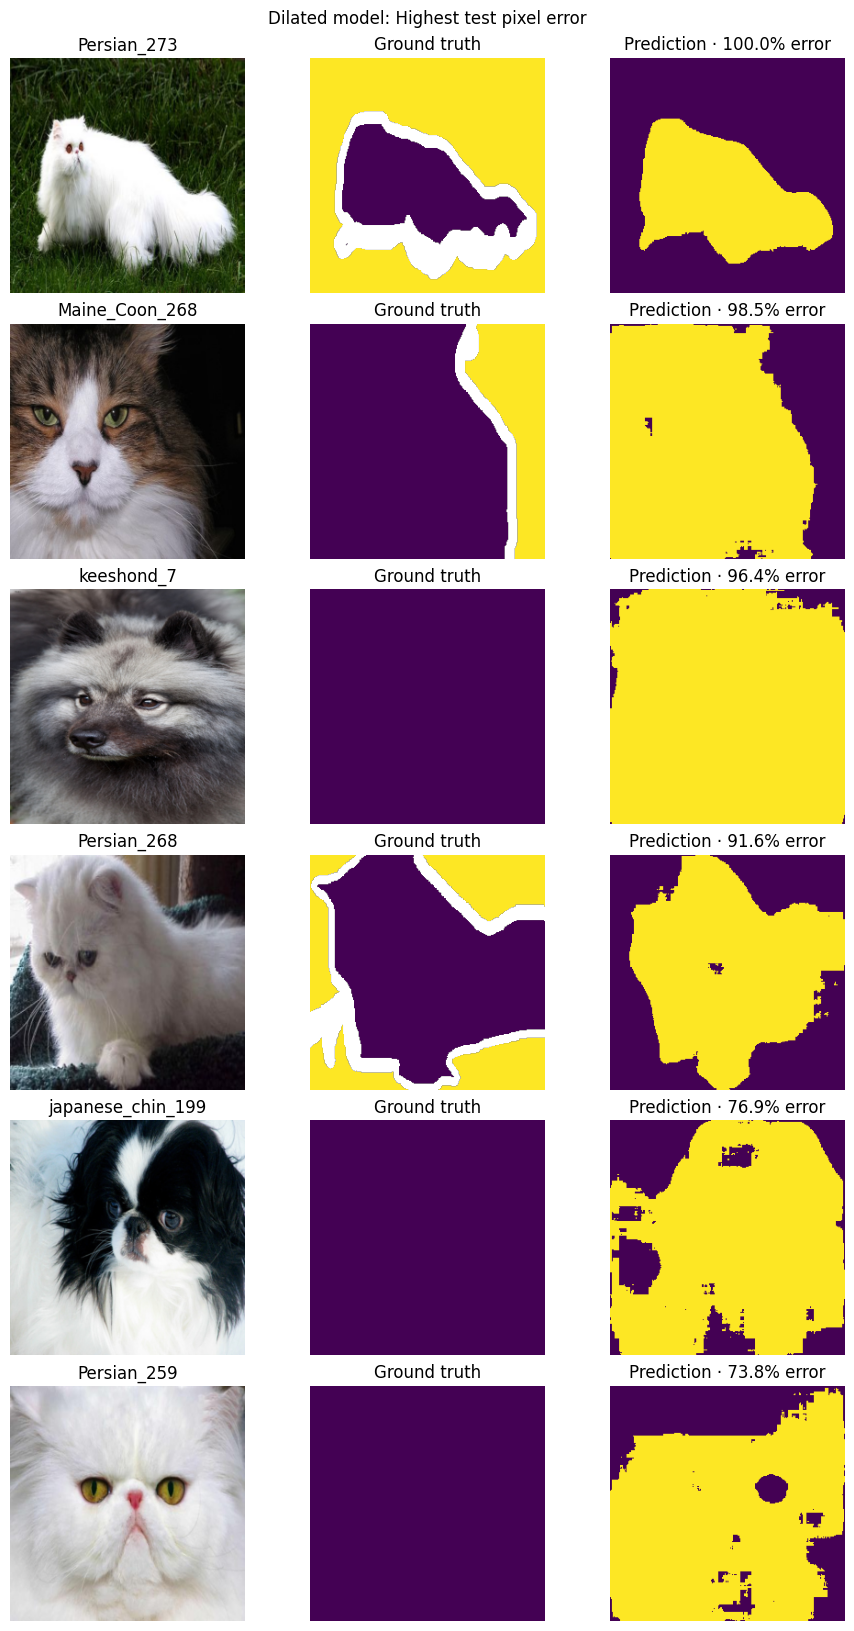

In [9]:
import matplotlib.pyplot as plt

summary = json.loads((run_dir / "results.json").read_text(encoding="utf-8"))
histories = json.loads((run_dir / "history.json").read_text(encoding="utf-8"))
labels = {"baseline": "Baseline (dilation 1)", "dilated": "Dilated bottleneck (dilation 2)"}
split_name = "official test split" if summary["official_test_split"] else "fallback held-out split"
print(f"{'Smoke test subset of the ' if summary['smoke_test'] else 'Results on the '}{split_name}. "
      f"Processes: {summary['training_processes']}, elapsed: {summary['elapsed_minutes']:.1f} min.")
def show_iou(x):
    return f"{x:.4f}" if x is not None else "n/a"
print(f"{'Model':34} {'BG IoU':>8} {'Pet IoU':>8} {'mIoU':>8} {'Params':>11} {'ms/image':>10} {'Best / total epochs':>19}")
for key, row in summary["results"].items():
    print(f"{labels[key]:34} {show_iou(row['background_IoU']):>8} {show_iou(row['pet_IoU']):>8} "
          f"{row['mIoU']:8.4f} {row['parameters']:11,d} {row['latency']['ms_per_image']:10.3f} "
          f"{row['best_epoch']:>10} / {row['epochs_run']} ({row['stop_reason']})")
lat = summary["results"]["baseline"]["latency"]
print(f"Latency: single {lat['device']}, {lat['precision']}, batch {lat['batch_size']}; "
      f"{lat['warmup']} warmup + {lat['repeats']} timed forwards. Excludes reading data and host-to-device transfer.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for key, hist in histories.items():
    epochs = [row["epoch"] for row in hist]
    axes[0].plot(epochs, [row["train_loss"] for row in hist], marker="o", label=labels[key])
    axes[1].plot(epochs, [row["val_miou"] for row in hist], marker="o", label=labels[key])
axes[0].set(title="Training cross-entropy", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="Validation mean IoU", xlabel="Epoch", ylabel="mIoU", ylim=(0, 1))
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
fig.savefig(run_dir / "training_curves.png", dpi=150)
plt.show()

meta = json.loads((run_dir / "dataset.json").read_text(encoding="utf-8"))
test_ids = meta["ids"][-meta["counts"]["test"]:]
examples_path = run_dir / "examples.npz"
if examples_path.exists():
    with np.load(examples_path, allow_pickle=False) as examples:
        for group, title in [("representative", "Representative predictions below 15% pixel error"),
                             ("highest", "Highest test pixel error")]:
            rows = np.flatnonzero(examples["groups"] == group)
            if not len(rows):
                print("No held-out examples below 15% pixel error.")
                continue
            fig, axes = plt.subplots(len(rows), 3, figsize=(9, 2.7 * len(rows)),
                                     layout="constrained", squeeze=False)
            fig.suptitle(f"Dilated model: {title}")
            for ax, j in zip(axes, rows):
                ax[0].imshow(examples["images"][j])
                ax[0].set_title(test_ids[examples["indices"][j]])
                ax[1].imshow(np.ma.masked_equal(examples["masks"][j], 255), cmap="viridis", vmin=0, vmax=1)
                ax[1].set_title("Ground truth")
                ax[2].imshow(examples["predictions"][j], cmap="viridis", vmin=0, vmax=1)
                ax[2].set_title(f"Prediction · {examples['errors'][j]:.1%} error")
                for panel in ax:
                    panel.axis("off")
            fig.savefig(run_dir / f"{group}_error_examples.png", dpi=150)
            plt.show()

In [10]:
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

from IPython.display import FileLink, display

# Or set RUN_DIR = Path("/kaggle/working/oxford_pet_ddp/your_run")
RUN_DIR = globals().get("run_dir")
if RUN_DIR is None:
    raise ValueError("Set RUN_DIR to your completed run folder.")

source = Path(RUN_DIR).resolve()
required = {"baseline_best.pt", "dilated_best.pt", "results.json"}
missing = sorted(name for name in required if not (source / name).is_file())
if missing:
    raise FileNotFoundError(f"Missing in {source}: {', '.join(missing)}")

zip_path = Path("/kaggle/working") / f"{source.name}_heldout_and_weights.zip"
files = sorted(file for file in source.iterdir() if file.is_file() and file.suffix != ".tmp")

with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as archive:
    for file in files:
        archive.write(file, arcname=f"{source.name}/{file.name}")

print(f"Packed {len(files)} files ({zip_path.stat().st_size / 2**20:.1f} MiB)")
display(FileLink(zip_path.relative_to(Path.cwd()) if zip_path.is_relative_to(Path.cwd()) else zip_path))

Packed 12 files (17.8 MiB)


/kaggle/working/full_20261114_150454_05d10a_plus20_dcbf33_heldout_and_weights.zip

In [11]:
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

from IPython.display import FileLink, display

# Set RUN_DIR to a specific run folder to override the current selection.
RUN_DIR = globals().get("run_dir")
if RUN_DIR is None:
    raise ValueError("Run the restore cell first or set RUN_DIR to your completed run.")

source = Path(RUN_DIR).resolve()
required = ("results.json", "history.json", "baseline_best.pt", "dilated_best.pt")
missing = [name for name in required if not (source / name).is_file()]
if missing:
    raise FileNotFoundError(f"Missing from {source}: {', '.join(missing)}")

groups = {
    "qualitative_results": [
        source / "examples.npz",
        *sorted(source.glob("*_error_examples.png")),
    ],
    "quantitative_results": [source / "results.json"],
    "checkpoints": [
        source / name for name in (
            "baseline_best.pt",
            "dilated_best.pt",
            "history.json",
            "training_curves.png",
            "config.json",
            "dataset.json",
            "train.log",
        )
    ],
}

zip_path = Path("/kaggle/working") / f"{source.name}_organized_results.zip"
with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as archive:
    for folder, files in groups.items():
        archive.writestr(f"{folder}/", b"")
        for file in files:
            if file.is_file():
                archive.write(file, arcname=f"{folder}/{file.name}")

print(f"Created {zip_path} ({zip_path.stat().st_size / 2**20:.1f} MiB)")
link = zip_path.relative_to(Path.cwd()) if zip_path.is_relative_to(Path.cwd()) else zip_path
display(FileLink(link))

Created /kaggle/working/full_20261114_150454_05d10a_plus20_dcbf33_organized_results.zip (17.8 MiB)


/kaggle/working/full_20261114_150454_05d10a_plus20_dcbf33_organized_results.zip

## 6. Interpretation and references

Use the measured table above to describe whether the dilation change improved pet IoU or mIoU and what latency cost it introduced. This notebook does not claim the dilated model is better in advance; report the observed results from your Kaggle run. Checkpoint selection uses the validation split, and the official test split is reserved for final comparison.

**References**
- Parkhi et al., *Cats and Dogs*, IEEE CVPR 2012, Oxford-IIIT Pet dataset: https://www.robots.ox.ac.uk/~vgg/data/pets/
- Ronneberger et al., *U-Net: Convolutional Networks for Biomedical Image Segmentation*, MICCAI 2015: https://arxiv.org/abs/1505.04597
- PyTorch documentation: https://pytorch.org/docs/stable/
